# `stochastics.finance` — order book, agents and the exchange (versions 5–7)

The agent-based market is built from three layers, each usable on its own:

| module | what it is |
|---|---|
| `lob.OrderBook` | limit order book with price–time priority (a tested port of your `OrderBook.js`) |
| `agents` | trader types (your `bots.js` plus the brief's personalities and a utility trader), each a small class with an `on_tick(m)` |
| `exchange.simulate` | a population of agents trading through the book for a simulated day: the schedule, news, attention, results |
| `profiles` | version 7: traders defined by a **psychology vector** mapped to behaviour by replaceable functions |

```python
from stochastics.finance import exchange
res = exchange.simulate('game', seed=1)      # the website's ~1,000-agent day
res.summary(); res.by_type(); res.plot()
```

In [14]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from stochastics.finance import exchange, agents
from stochastics.finance.lob import OrderBook, BUY, SELL
from stochastics.finance.profiles import Profile, ProfiledTrader, Behavior, sample_profiles

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.0f}' if abs(v) >= 1e4 else f'{v:.4g}')

## The order book

Limit orders match what crosses and the rest rests; market orders never rest; a trade happens at the
*resting* order's price; within a price level the oldest order goes first.

In [15]:
book = OrderBook()
book.on_trade(lambda t: print('trade', t))
book.limit('maker', SELL, 100.05, 50)
book.limit('maker', BUY, 99.95, 50)
book.limit('other', SELL, 100.10, 30)
print(book.market('taker', BUY, 60))          # eats 50 @ 100.05 and 10 @ 100.10
print('bid', book.best_bid(), 'ask', book.best_ask(), 'mid', book.mid(), 'spread', book.spread())
print(book.levels(SELL, 3), book.levels(BUY, 3))
book.check()

trade Trade(price=100.05, qty=50, buyer='taker', seller='maker', buy_order='b4', sell_order='b1', aggressor='BUY')
trade Trade(price=100.1, qty=10, buyer='taker', seller='other', buy_order='b4', sell_order='b3', aggressor='BUY')
Fill(id='b4', filled=60, avg_price=100.05833333333334, resting=0)
bid 99.95 ask 100.1 mid 100.025 spread 0.15
[(100.1, 20)] [(99.95, 50)]


Your JavaScript `OrderBook.js` and this book were run on the same 11,689 random operations: every trade,
fill, resting quantity and book level was identical.

## A trading day (version 5 and 6)

`'game'` is the website's population (about 1,000 agents: 90% noise traders of four kinds, 10% market makers,
whales, trend followers, mean reverters...), with the day's schedule: an opening crowd, hourly arrivals and
departures, the US-open directional cohort at 14:30 and a closing crowd. Time runs in 15-second ticks from
09:30 to 18:00. Python's random numbers are not bit-identical to the JavaScript ones, so the *distributions*
agree, not each path (see the end of the notebook).

In [16]:
res = exchange.simulate('game', seed=1)
res.summary()

ticks                     2040
agents ever               1501
active at close           1099
trades                 100,863
shares traded          978,111
open                     99.97
close                    98.48
high                     100.2
low                      98.41
day return            -0.01515
annualised vol          0.1539
mean spread (cents)      4.895
two-sided quotes             1
seconds to simulate       17.6
Name: exchange day, dtype: float64

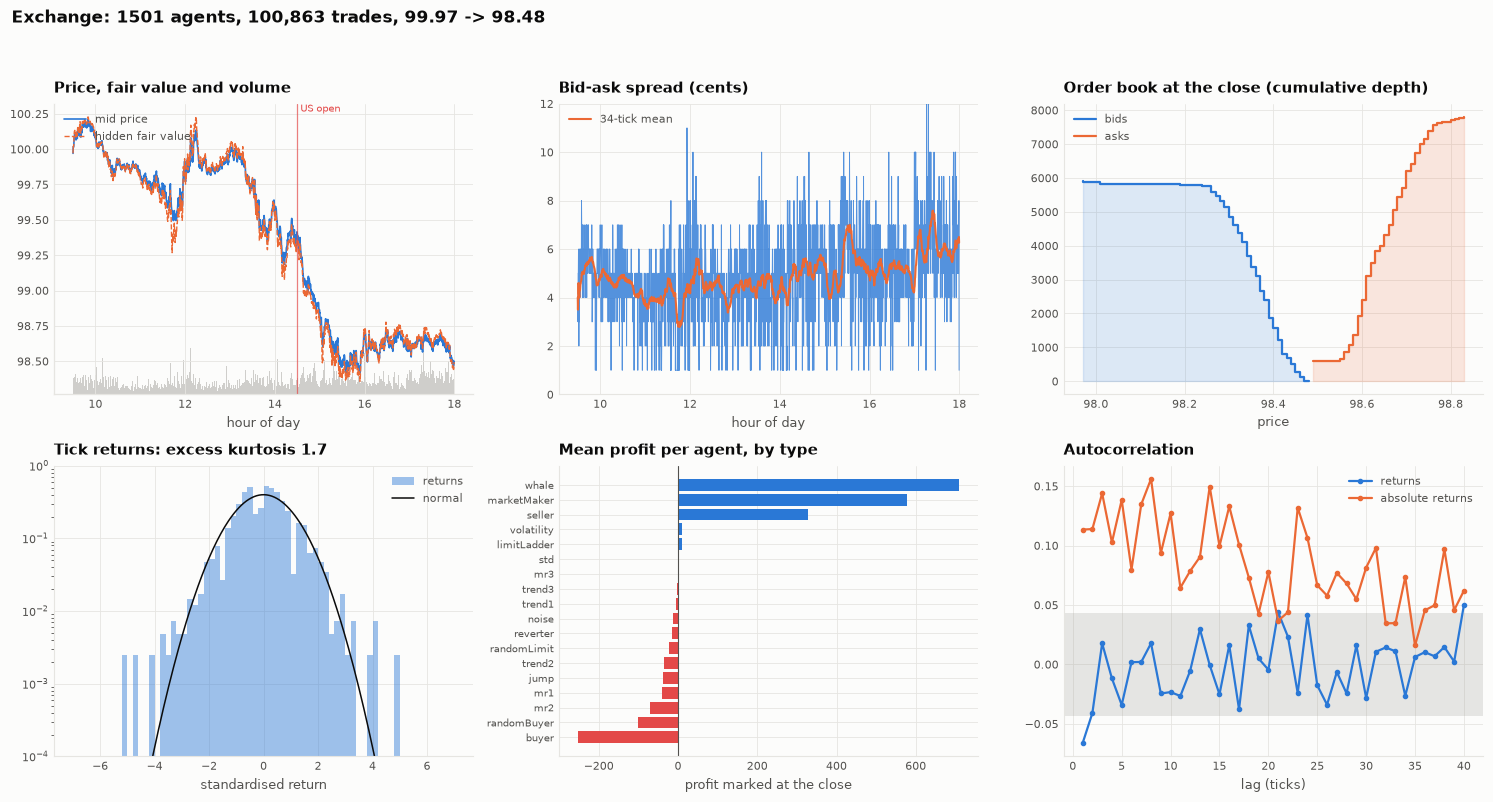

In [17]:
res.plot()

**Who makes money?** Profit is marked to the closing mid. Every trade has a buyer and a seller, so the books must
balance exactly; `conservation()` checks it.

In [18]:
display(res.by_type())
res.conservation()

,agents,mean pnl,total pnl,sd pnl,profitable,shares traded,mean |position|,volume share
type,,,,,,,,
marketMaker,34,578.2,"19,658",469.9,0.8235,722623,89.32,0.3694
whale,7,709.5,4966,1102,0.7143,17387,1286,0.008888
seller,4,327.1,1309,92.98,1,1500,375,0.0007668
volatility,9,10.29,92.57,116.2,0.6667,8002,95.56,0.004091
limitLadder,5,9.23,46.15,5.755,0.8,70,2,3.578e-05
mr3,27,0.4807,12.98,12.25,0.3333,1420,8.889,0.0007259
std,6,0.67,4.02,9.166,0.1667,836,2.333,0.0004274
trend3,32,-3.186,-102,14.42,0.5938,2332,14.94,0.001192
trend1,31,-5.929,-183.8,18.61,0.2903,7353,2.097,0.003759


net change in shares                   0
net change in cash            -2.328e-10
total pnl                          -4325
pnl from initial endowments        -4325
dtype: float64

The market makers earn the most, and most of them finish the day ahead; the large crowd of noise traders pays
in total. The rule-based bots are mixed, and that is the point of the exercise: **a strategy's profit depends on who
else is in the market**, so change the mix and the ranking changes. One day is one draw: the ordering of the large
groups is stable from day to day, the small groups (a handful of whales) are not.

**Stylised facts of the price this population produces:**

In [19]:
res.facts().round(3)

annualised vol                0.154
skew                          0.054
excess kurtosis               1.687
tail index (Hill, top 5%)     4.942
acf(r), lag 1                -0.066
acf(|r|), lag 1               0.113
acf(|r|), lag 10              0.127
leverage corr(r, next r^2)    0.011
max drawdown                  0.018
dtype: float64

## The brief's personalities

`'brief'` is the version-6 mix: noise traders split into 20% value-anchored, 50% random and 30% genuine investors
(a running mean with stop-loss and take-profit), plus market makers, mean reverters (20/40 window cross,
price below 60MA − 1σ), whales, informed whales (which see some of the hidden fair value), trend followers (x% rise → buy,
sell after y% more, stop at z% fall) and volatility traders.

In [20]:
brief = exchange.simulate('brief', seed=2)
display(brief.summary())
brief.by_type()

ticks                    2040
agents ever              1368
active at close           984
trades                 97,640
shares traded         937,275
open                      100
close                     102
high                    102.7
low                     99.37
day return             0.0205
annualised vol         0.2645
mean spread (cents)     6.339
two-sided quotes            1
seconds to simulate      22.6
Name: exchange day, dtype: float64

,agents,mean pnl,total pnl,sd pnl,profitable,shares traded,mean |position|,volume share
type,,,,,,,,
marketMaker,34,693.8,"23,588",620.1,0.8529,851102,118,0.454
valueNoise,173,78.14,"13,518",160.5,0.5087,13615,18.58,0.007263
investor,261,45.23,"11,804",66.66,0.8467,45685,41.36,0.02437
noise,642,0.9388,602.7,271.7,0.4907,646173,148.1,0.3447
volatility,12,35.54,426.5,145.7,0.6667,9897,100.9,0.00528
trend3,16,15.23,243.7,22.41,0.75,4641,21.06,0.002476
mr1,20,7.715,154.3,10.26,0.85,9140,37.2,0.004876
trend1,28,-3.533,-98.91,30.76,0.5357,16506,0,0.008805
mr3,17,-19.89,-338.2,9.337,0.05882,5120,68.24,0.002731


## Your own population, your own agent

A population is a dict `{type: count}`. Extra agents join with `extra=[...]`; `PolicyAgent` is an empty slot:
its `policy(agent, m)` is called every tick with the market state `m` (price, `m.sma(n)`, `m.dev_z(n)`,
`m.move_z(k)`, `m.imbalance`, `m.value` ...).

In [21]:
def contrarian(agent, m):
    # lean against a stretched price with a limit order, flatten when the stretch is gone
    if abs(m.dev_z(60)) < 0.3:
        agent.cancel_all(); agent.flatten(); return
    if m.dev_z(60) > 2 and agent.shares > -300:
        agent.limit(SELL, m.mid + m.tick_sigma, 50, 20)
    if m.dev_z(60) < -2 and agent.shares < 300:
        agent.limit(BUY, m.mid - m.tick_sigma, 50, 20)

mine = [(agents.PolicyAgent, {'policy': contrarian, 'params': {'z': 2.0}}) for _ in range(25)]
r = exchange.simulate('game', seed=1, extra=mine)
r.by_type().loc[['policy', 'marketMaker', 'noise', 'whale']]

,agents,mean pnl,total pnl,sd pnl,profitable,shares traded,mean |position|,volume share
type,,,,,,,,
policy,25,-452.6,"-11,316",147.5,0,121364,0,0.04622
marketMaker,44,461,"20,282",345.7,0.9545,976711,147.8,0.372
noise,1099,-7.261,-7980,144,0.4813,1028920,132.7,0.3918
whale,9,-190.4,-1714,1283,0.2222,32392,1487,0.01234


## Version 5 — agents with internal wealth, risk aversion and learning

`UtilityTrader` holds a target fraction of its wealth in the stock: the mean-variance / Kelly share
$\;\mathrm{clip}\!\big((\mu/\sigma^2)/\text{risk aversion}\big)$, where $\mu$ is the gap between its **desired
price** and the market, and the desired price itself learns toward the market at `learning_rate`. It has a
stop-loss and a take-profit. More risk-averse traders trade much less. Their profits do not line up with risk
aversion in one day (the traders share a single price path, so the standard errors understate the day-to-day noise):
a single day cannot rank them.

In [22]:
rows = {}
for ra in (0.5, 2.0, 8.0):
    r = exchange.simulate('game', seed=3, ticks=900, record_trades=False,
                          extra=[(agents.UtilityTrader, {'risk_aversion': ra}) for _ in range(40)])
    a = r.agents[r.agents['type'] == 'utility']
    rows[f'risk aversion {ra}'] = {'shares traded per trader': a['volume'].mean(), 'mean pnl': a['pnl'].mean(),
                                   'pnl std error': a['pnl'].std() / np.sqrt(len(a))}
pd.DataFrame(rows).T

,shares traded per trader,mean pnl,pnl std error
risk aversion 0.5,3844,-56.2,10.36
risk aversion 2.0,2122,-7.377,5.87
risk aversion 8.0,776.5,-56.1,6.014


## Version 7 (first draft) — traders defined by their psychology

A `Profile` is just numbers; the work is in the *functions* that turn the numbers into trading. They live in
`Behavior`, one method each, so any of them can be replaced:

| trait | default mapping |
|---|---|
| `patience` | looks at the market `1/patience` as often; must hold `20·patience` ticks before a *signal* exit; patient traders rest limit orders, impatient ones pay the spread |
| `greed` | how stretched the signal must be to enter (`0.3 + 1.2·greed` σ) and how much profit it waits for |
| `resilience` | stop-loss distance; `1 − resilience` is the per-tick chance of bailing out of a losing position |
| `hypothesis` | `mean_reversion`, `trend`, `buy_hold` (belief only) or `noise` |
| `desired_price`, `internal_value` | the price it trades around; its perceived fundamental |
| `info` | how much of the market's hidden fair value leaks into its belief |
| `capital` | order size: bigger → whale-like |

```python
Profile(resilience=.5, greed=.5, patience=1, hypothesis='mean_reversion', capital=50_000)
```

In [23]:
mix = exchange.simulate('profiles', seed=4)           # noise + makers + 400 random profiles
by_h = mix.by_type(by='label')
by_h[by_h.index.str.startswith('profiled')]

,agents,mean pnl,total pnl,sd pnl,profitable,shares traded,mean |position|,volume share
label,,,,,,,,
profiled:buy_hold,103,-24.14,-2486,72.85,0.08738,26172,31.09,0.01356
profiled:trend,116,-25.41,-2948,120.4,0.319,113562,40.71,0.05882
profiled:mean_reversion,131,-27.95,-3662,165,0.2901,156174,48.72,0.08089
profiled:noise,121,-37.34,-4518,112.4,0.2645,222062,42.21,0.115


One day is one draw. To see which **traits** pay, pool the profile traders over several days (each run ~4 s):

In [24]:
frames = []
for seed in range(6):
    r = exchange.simulate('profiles', seed=seed, ticks=1200, record_trades=False)
    ids = r.agents.index[r.agents['type'] == 'profiled']
    d = r.traits.loc[ids].join(r.agents.loc[ids, ['pnl', 'volume', 'label']])
    d['day'] = seed
    d['pnl'] = d['pnl'] - d.groupby('day')['pnl'].transform('mean')       # remove the day's common level
    frames.append(d)
pooled = pd.concat(frames)
rows = []
for col in ['resilience', 'greed', 'patience', 'log_capital', 'info']:
    rho, p = stats.spearmanr(pooled[col], pooled['pnl'])
    rows.append({'trait': col, 'spearman with pnl': rho, 'p-value': p})
display(pd.DataFrame(rows).set_index('trait'))
pooled.groupby('label')[['pnl', 'volume']].mean()

,spearman with pnl,p-value
trait,,
resilience,0.02129,0.2565
greed,0.03543,0.05892
patience,0.163,2.166e-18
log_capital,-0.2423,2.895e-39
info,-0.07791,3.201e-05


,pnl,volume
label,,
profiled:buy_hold,17.24,212.5
profiled:mean_reversion,2.631,831.1
profiled:noise,-9.377,1046
profiled:trend,-10.04,702.3


**Reading this honestly.** **Patience is the one trait that clearly pays** (rank correlation about +0.16 with profit after removing each day's
average): patient traders look at the market less often and rest limit orders instead of paying the spread, so they
trade less. Larger capital does worse in dollars (about -0.24), the most likely reason being that bigger orders pay
more spread and impact. Resilience and greed matter little, and `info` is slightly *negative*. By hypothesis,
buy-and-hold, which trades least, comes out best and the noise hypothesis and trend following worst.

The last question is why `info` does not pay: a trader who sees the market's hidden fair value should win. The
gap between that value and the price, and what the price does next:

In [25]:
rows = {5: [], 20: [], 60: []}
for seed in range(10):                                     # ten days; one day's correlation is very noisy
    r = exchange.simulate('game', seed=seed, ticks=1500, record_trades=False)
    gap = (r.value - r.price) / r.price
    for k in rows:
        rows[k].append(np.corrcoef(gap[:-k], r.price[k:] / r.price[:-k] - 1)[0, 1])
pd.DataFrame({f'{k} ticks ahead': {'mean corr(gap, later return)': np.mean(v),
                                   'std error': np.std(v, ddof=1) / np.sqrt(len(v)),
                                   'days with corr > 0': int(np.sum(np.array(v) > 0))}
              for k, v in rows.items()}).T

,"mean corr(gap, later return)",std error,days with corr > 0
5 ticks ahead,-0.03015,0.01529,3
20 ticks ahead,-0.1137,0.02146,0
60 ticks ahead,-0.2231,0.02921,0


In this engine the hidden value is **not a leading indicator**: averaged over days the gap has a *negative*
correlation with the following return, growing with the horizon (it is not stable from one day to the next).
That is what you would expect if the value lags the price (it is pulled 2% per tick toward the mid) while the price
has some short-term momentum, so a positive gap mostly means the price has just fallen. I also tried the obvious repair, making the makers quote around
the price instead of the value: then the news has no way into the price at all and informed traders still lose.
For information to pay, the price has to react to the value *with a lag*, for example through a group of traders who
see the news late. That is a design decision about your market, so I have left it as it is.

### A learned policy

`ProfiledTrader(policy=...)` replaces the rule engine; `trader.features(m)` is a fixed-length observation vector
(market z-scores, order-book imbalance, volatility rank, position, P&L, holding time, the trader's own traits).
That is where a GRU or an RL agent plugs in — no neural-network dependency is needed in the package.

In [26]:
from stochastics.finance.profiles import FEATURE_NAMES
seen = []
def peek(trader, m):
    seen.append(trader.features(m))
exchange.simulate('minimal', seed=1, ticks=300, schedule=False, record_trades=False,
                  extra=[(ProfiledTrader, {'profile': Profile(patience=2.0, greed=.3), 'policy': peek})])
pd.DataFrame(seen, columns=FEATURE_NAMES).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
dev_z_60,0.5576,0.6476,-0.7157,2.139
move_z_10,0.4453,0.9239,-2.68,2.553
move_z_30,0.6697,0.702,-1.407,2.524
imbalance,-0.03226,0.1225,-0.3631,0.2903
vol_rank,0.4058,0.2905,0,0.9948
heat,0.847,0.219,0.5,1.407
belief_gap_pct,-0.5038,0.3005,-1.078,0.04502
position_value / capital,0,0,0,0
pnl_pct,0,0,0,0
holding_ticks / 100,0,0,0,0


## How close is this to your JavaScript engine?

Both engines were run for 40 seeds each (the JS one in Node, unchanged, apart from a stub for `ai/RLTrader.js`).
Means (standard deviation across seeds in brackets) of the day's statistics:

| statistic | JavaScript | Python | Welch p |
|---|---|---|---|
| trades | 116,687 (8,918) | 111,447 (12,107) | 0.03 |
| shares traded | 1.137M (87k) | 1.099M (118k) | 0.10 |
| annualised vol | 0.219 (0.053) | 0.205 (0.037) | 0.19 |
| excess kurtosis | 3.46 (5.2) | 3.36 (2.7) | 0.91 |
| mean spread (cents) | 5.20 (0.48) | 5.09 (0.35) | 0.24 |
| high–low range | 2.11% (0.59%) | 2.03% (0.64%) | 0.56 |
| acf(\|r\|), lag 1 | 0.237 (0.059) | 0.235 (0.076) | 0.89 |

Volatility, tails, spread, range and volatility clustering agree; trade counts differ by about 5% (an earlier
16-seed comparison showed a difference of similar size in the opposite direction, so I treat it as sampling noise
rather than a porting error — but it is not bit-identical, because the random-number generators differ).

# Real intraday data: how close are versions 5–7 to a real trading day?

Notebook 06 scored versions 1–4, a stochastic-volatility variant of version 3 and three standard baselines against daily data. Here the same benchmark
(twelve scale-free facts; error in units of the real series' own sampling noise; see notebook 06 for the method) is
applied to intraday data, where the agent-based exchange can be compared with real bars.

* **Real data**: a 5-minute equity index (21 January-2006 sessions of 102 bars), 5-minute Bitstamp BTC/USD bars
  (10 days resampled from 1-minute data), and hourly EUR/USD (April 2017 – February 2018). There is no free
  minute-level FX in the sample sets, so **FX is scored for versions 1–4 and the baselines only**; the exchange has
  an 8.5-hour day and is compared with the equity index and with crypto, which trades round the clock.
* **Exchange candidates**: `'agents'` (version 5: noise, random-limit, maker and whale background plus 400 utility
  traders), `'brief'` (version 6), `'profiles'` (version 7: 400 psychology-profile traders) and the website's
  `'game'` population. They are assessed **as designed, not tuned**: they have too many parameters and a day costs
  seconds. The quick models are tuned, so the comparison favours them. Keep that in mind when reading it.
* A simulated day costs seconds, so each exchange candidate is simulated once into a pool of independent days, and
  replicates are drawn from the pool by resampling days. This understates the model's own spread a little (the
  p-values are slightly optimistic about rejecting), but the cost per replicate is reported as the real cost of the
  days a replicate needs.

In [1]:
import time
from stochastics.finance import realdata, benchmark as bm

QUICK = False                         # True: a few-minute version with small budgets (rougher numbers)
REPS, BUDGET, CAL_REPS = (8, 24, 4) if QUICK else (24, 70, 6)
POOL = 6 if QUICK else 24             # simulated days per exchange candidate
N_JOBS = 2

ix = realdata.sample('index_5m')
btc = realdata.sample('btc_1m').resample('5min').window(last=288 * 10)
btc.name = 'btc_5m'
fx = realdata.sample('eurusd_1h').sessions(120)       # weekly stretches cut into sessions of 120 hours
intraday = {'index_5m': ix, 'btc_5m': btc, 'eurusd_1h': fx}
pd.DataFrame({n: s.summary() for n, s in intraday.items()}).T

NameError: name 'pd' is not defined

### Intraday fingerprints next to their daily counterparts

Intraday returns are more clustered and heavier-tailed than daily ones, and carry a time-of-day pattern in volatility
(the opening and closing hours are busier) that the fingerprint does not remove.

In [28]:
daily = {'sp500 (daily)': realdata.sample('sp500'), 'btc_d (daily)': realdata.sample('btc_d').window(last=3500),
         'eur_d (daily)': realdata.sample('eur_d').window(last=5000)}
facts = pd.DataFrame({**{n: s.fingerprint() for n, s in intraday.items()}, **{n: s.fingerprint() for n, s in daily.items()}})
facts[['index_5m', 'sp500 (daily)', 'btc_5m', 'btc_d (daily)', 'eurusd_1h', 'eur_d (daily)']].round(2)

,index_5m,sp500 (daily),btc_5m,btc_d (daily),eurusd_1h,eur_d (daily)
skew,-0.18,-0.2,1.2,-0.66,0.07,-0.16
log kurtosis,2,2.41,3.37,2.71,2.64,1.88
log tail index,1.17,1.08,0.97,1.18,1.09,1.33
tail/body ratio,6.36,6.31,6.2,6.97,5.56,5.18
acf(r) lag 1,-0.01,-0.07,0,-0.04,-0.02,0.02
acf(|r|) lag 1,0.24,0.25,0.24,0.19,0.16,0.12
acf(|r|) lag 5,0.19,0.33,0.26,0.16,0.06,0.15
acf(|r|) lag 20,0.05,0.24,0.11,0.09,0.05,0.17
leverage,-0.03,-0.11,0.06,-0.05,0,-0
vol of vol,1.02,1.01,1.09,0.9,0.69,0.78


### Step 1 — baselines and versions 1–4, tuned to each intraday series

636 s


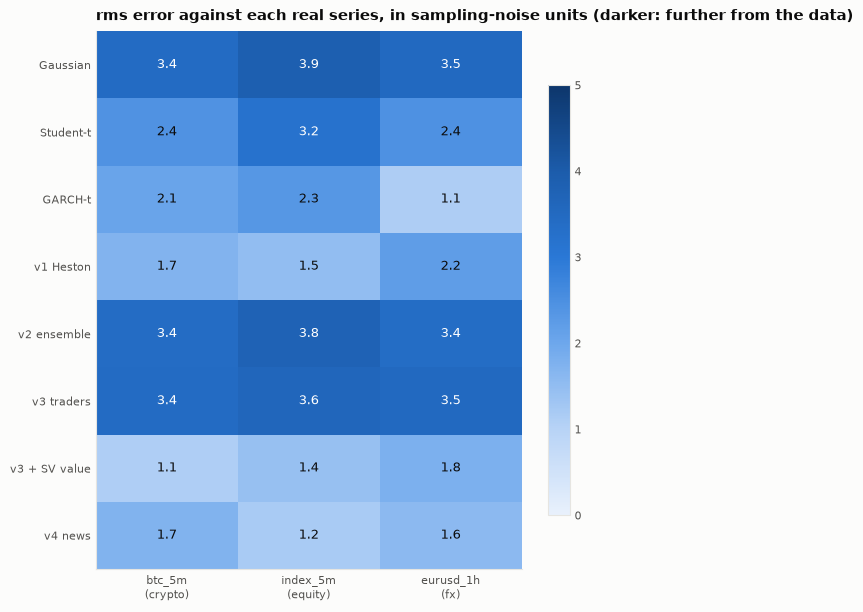

,index_5m,btc_5m,eurusd_1h
model,,,
Gaussian,3.86,3.42,3.5
Student-t,3.2,2.44,2.44
GARCH-t,2.34,2.05,1.12
v1 Heston,1.49,1.7,2.2
v2 ensemble,3.76,3.42,3.37
v3 traders,3.61,3.42,3.5
v3 + SV value,1.43,1.1,1.78
v4 news,1.17,1.73,1.57


,,nu,alpha,beta,gamma,halflife,cv,rho,correlation,w_heston,w_merton,jump_size,crowd,value_halflife,value_cv,value_rho,events,jump_scale,branching,underreaction
model,series,,,,,,,,,,,,,,,,,,,
Student-t,index_5m,3.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GARCH-t,index_5m,60,0.19,0.7,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
v1 Heston,index_5m,NaN,NaN,NaN,NaN,9.74,1.09,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
v2 ensemble,index_5m,NaN,NaN,NaN,NaN,NaN,3,NaN,0.95,1,0.43,1.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
v3 traders,index_5m,NaN,NaN,NaN,NaN,3.61,NaN,NaN,NaN,NaN,NaN,NaN,1.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
v3 + SV value,index_5m,NaN,NaN,NaN,NaN,32.05,NaN,NaN,NaN,NaN,NaN,NaN,2,10.88,1.51,-0.05,NaN,NaN,NaN,NaN
v4 news,index_5m,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,10,6.57,0.53,0
Student-t,btc_5m,2.74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GARCH-t,btc_5m,10,0.26,0.95,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
quick_models = [bm.Gaussian(), bm.StudentT(), bm.GARCH(), bm.Heston(), bm.Ensemble(), bm.Traders(), bm.TradersSV(), bm.News()]
t0 = time.time()
sw_q = bm.sweep(intraday, quick_models, n_jobs=N_JOBS, replicates=REPS, calibrate_budget=BUDGET, cal_replicates=CAL_REPS)
print(f'{time.time() - t0:.0f} s')
sw_q.plot()
display(sw_q.rms.round(2))
display(sw_q.parameters().round(2))

### Step 2 — the agent-based exchange: versions 5, 6, 7 and the web game

Each candidate is simulated once into a pool of independent trading days (5-minute bars from 15-second ticks), using
both cores. The table shows what a day costs.

In [2]:
exchange_models = [
    bm.Exchange(population='agents',   pool_days=POOL, label='v5 agents'),
    bm.Exchange(population='brief',    pool_days=POOL, label='v6 brief'),
    bm.Exchange(population='profiles', pool_days=POOL, label='v7 profiles'),
    bm.Exchange(population='game',     pool_days=POOL, label='web game'),
]
t0 = time.time()
for m in exchange_models:
    m.prepare(n_jobs=N_JOBS)
print(f'{time.time() - t0:.0f} s to simulate {POOL} days for each of the four populations')
pd.DataFrame({m.label: {'agents': sum(m._mix().values()), 'seconds per day (one core)': m.seconds_per_day,
                        'returns per day': len(m.pool()[0][0])} for m in exchange_models}).T.round(2)

1426 s to simulate 24 days for each of the four populations


NameError: name 'pd' is not defined

In [ ]:
sw_x = bm.sweep({'index_5m': ix, 'btc_5m': btc}, exchange_models, replicates=REPS)
sw_all = sw_q.only(['index_5m', 'btc_5m']) + sw_x            # twelve candidates on the two series both can face
sw_all.plot()
display(sw_all.rms.round(2))
cols = ['rms error', 'facts within 2', 'p-value', 'seconds / replicate', 'worst fact']
for n in ('index_5m', 'btc_5m'):
    print(n)
    display(sw_all.boards[n].table[cols].round(3))

In [ ]:
sw_all.plot_facts(signed=True)

Fact by fact for the exchange populations against the equity index (dots: individual replicates; diamond: mean;
grey band ±1 noise unit):

In [ ]:
sw_all.boards['index_5m'].assessments['v6 brief'].plot()
sw_all.boards['index_5m'].assessments['v6 brief'].table().round(3)

## What the intraday data say

**1. The same two groups appear at 5-minute and hourly resolution.** Averaged over the three series, Gaussian (3.59),
Student-t (2.69), version 2 (3.52) and version 3 (3.51) have no volatility clustering and sit far from the data; Heston (1.80),
GARCH-t (1.84), version 4 (1.49) and version 3 with a stochastic-volatility value (1.44) have it. As on the daily data, the
Gaussian value inside version 3 is what fails: replace it and the error falls from 3.5 to 1.4. There is again no stable winner among the four that work:
version 4 is best on the equity index (1.17), version 3-SV on BTC (1.10), and a plain GARCH-t on hourly EUR/USD (1.12), the calmest series, where
the simplest model is enough. The series are short (21 sessions, 10 days, 42 weekly stretches) and nothing here was held out,
so differences of a few tenths among those four are not reliable.

**2. The exchange, untuned, lands about level with a tuned GARCH-t.** On the equity index versions 6 (2.25) and the web game (2.13)
are close to GARCH-t (2.34) and well ahead of the models with no volatility clustering (3.2–3.9); on BTC they are 2.11 and 1.58 against GARCH-t's 2.05.
They are behind tuned Heston, version 3-SV and version 4 on the index (1.2–1.5). On BTC the web game (1.58) is level with Heston and version 4 (1.70, 1.73) and version 6 is 0.4 behind them.
The catch is how much has been tuned: the quick models were fitted to each series with about 70 evaluations,
the exchange populations were run as designed. Nobody knows what tuning would do for the exchange, because one evaluation costs minutes (see the speed section).
Versions 5 and 7 are level with each other (2.7 and 2.6 on both series) and version 6 improves on them by 0.4–0.5, so the
step from the 'agents' population to the 'brief' one is a measurable gain, and the profile-based population of version 7, a first draft, has not yet
earned one. On the formal test no exchange version is accepted on either series (p = 0.04 is the smallest value possible here); on the index Heston,
3-SV and version 4 are accepted, and on BTC every model except GARCH-t is rejected, so the test cannot separate them there.

**3. Volatility clustering comes out of the trading rules.** None of it is put in as a volatility process, yet the exchange versions are within
about 2.4 noise units on the lag-1, lag-5 and lag-20 autocorrelation of absolute returns and on vol of vol (versions 6 and 7 and the web game; version 5's
lag 1 is 3.6 too high), where the models without clustering are 4.5–7.4 off on lags 1 and 5 and on vol of vol. It is a little weak at long
lags: `acf(|r|)` at lags 5 and 20 is up to 2.4 noise units too low in versions 5–7.

**4. Where the exchange differs, and the differences have different signs.** Averaged over the index and BTC, version 5 has a lag-1 return autocorrelation
that is far too *negative* (−9 noise units) and variance ratios that are too low (−6.4 at 5 bars): it over-reverts, the signature of price bouncing between bid and ask. Version 7 is the mirror image: lag-1 too *positive* (+5.1), variance ratios too high (+6.2 at 5 bars, +3.2 at 20): it
over-trends. Versions 6 and the web game over-trend at 20 bars (+3.0 and +4.3). For version 6 this is mostly the equity index, whose real 20-bar
variance ratio is 0.65 (+5.6 noise units on the index, about +0.4 on BTC, where the real value is 1.09): the exchange fits crypto's momentum better than
equities' mean reversion. Versions 6 and 7 and the web game have tails that are too thin by the Hill index (+3.1, +1.9, +1.5 noise units; version 5 does not) and version 6's
log kurtosis is 2.3 too low. These are concrete targets: the populations' mix of trend-following and mean-reverting rules is what to adjust,
and version 5 against version 7 shows the two directions it can be wrong in.

**Limits.** Three small public samples (one month of an equity index in 2006, ten days of BTC in 2025, hourly EUR/USD); no hold-out on
intraday data because the series are too short to split; the time-of-day pattern in volatility is not removed from the fingerprint (the exchange has an
intraday schedule, the quick models do not); the exchange's day is 8.5 hours while BTC trades around the clock; one pool of simulated days per population.
The `rms se` column only resamples days within the pool; the pool-size study below suggests that a pool's own sampling error is of the order of 0.1–0.2,
so exchange-to-exchange gaps below that, such as version 6 against the web game, cannot be called.

## Speed against accuracy, intraday

### 1. All twelve candidates, two series

In [ ]:
ca = sw_all.cost_accuracy()
display(ca.round(3))
bm.plot_frontier(ca, title='Twelve ways to simulate a market: mean over the equity index and BTC (5-minute bars)')

### 2. What does a bigger, finer exchange buy?

Version 6 (`'brief'`) with its population scaled by 0.25, 0.5 and 1, and with the engine's time step set to 15, 30
and 60 seconds (the 5-minute bars are the same). Scored against the equity index.

In [ ]:
KPOOL = 4 if QUICK else 16
knob = [bm.Exchange(population='brief', scale=sc, sim_secs_per_tick=tk, pool_days=KPOOL, label=f'x{sc:g}, {tk}s tick')
        for sc in (0.25, 0.5, 1.0) for tk in (15, 30, 60)]
t0 = time.time()
for m in knob:
    m.prepare(n_jobs=N_JOBS)
print(f'{time.time() - t0:.0f} s to build the nine pools')
fr = bm.frontier(ix, knob, replicates=REPS)
display(fr.round(3))
bm.plot_frontier(fr, title='Version 6: population size and time step, against the equity index')

### 3. How many simulated days are enough?

The first `k` days of the version-6 pool, scored against the equity index (the pool's days are the same, so this
costs nothing extra).

In [ ]:
base = exchange_models[1]
rows = {}
for k in (2, 4, 8, 16, POOL):
    a = bm.assess(ix, base.variant(pool_days=k), replicates=REPS)
    rows[k] = {'rms error': a.rms_error, 'rms se': a.rms_se(), 'p-value': a.p_value, 'facts within 2': a.within,
               'seconds to simulate': k * base.seconds_per_day}
pd.DataFrame(rows).T.rename_axis('days in pool').round(3)

## What the intraday speed–accuracy study says

**Across models.** The quick models cost 0.002–0.05 s per replicate and the exchange 160–240 s (one core): **3,000 to 8,500 times more than versions 3-SV
and 4, and 27,000 to 39,000 times more than GARCH-t**. The Pareto-optimal candidates are Gaussian, Student-t, GARCH-t, version 3-SV and version 4, and the
knee is **version 4** (error 1.45 at 0.03 s, averaged over the index and BTC). No exchange population is on the frontier: the best of them (the web game, 1.85)
is worse than version 4 and 6,000 times as expensive, and version 6 (2.18) is level with GARCH-t (2.20) at about 27,000 times the cost. Counting the
tuning of the quick models does not change this (the whole sweep, eight models tuned on three series, took about four minutes). The exchange is not the efficient way to reproduce these
statistics; what it offers instead, individual traders with their own books, is something the quick models cannot say anything about.

**Time step.** A 60-second engine step is about 4 times cheaper than 15 seconds with no loss of accuracy: at the full population 2.27 against 2.33 (the difference is inside the noise), and
2.33 against 2.48 at half the population. The 5-minute bars are the same, only the number of trading rounds inside each changes.

**Population size.** Cost falls less than the population: 250 agents (scale 0.25) cost 2.3 to 2.6 times less per day than 1,000, not 4, so there is a fixed
cost per step. Accuracy falls slowly: at a 60-second step the errors are 2.53, 2.33 and 2.27 for 250, 500 and 1,000 agents. The **knee is
250 agents at a 60-second step** (2.53 at 14 s per replicate against 2.33 at 135 s for the default). Half the population at 60 s (2.33 at 21 s) matches the
default's accuracy at about a sixth of its cost. The settings are not independent: 250 agents at a 15-second step is an outlier (3.67), far worse than the same
population at 30 seconds (2.51). A six-day check shows why in the facts: its variance ratios are far too high (about 2.6 at 20 bars against 0.65 in the data), so it trends
too strongly. I did not look for the cause, so treat a knob that looks harmless as untested until its fingerprint has been looked at.

**Days in the pool.** The score is poor with few days and settles: 3.48 with 2 days, 2.86 with 4, 2.44 with 8, 2.33 with 16, 2.25 with 24 (and 3, 6, 8, 8, 8 of the twelve facts within 2 noise units).
**At least 8 days are needed, 16 is safer**: going from 8 to 24 days buys 0.19 for three times the cost, going from 2 to 8 buys 1.0. Small pools are bad because
a replicate built from a few days inherits their sampling noise. The 24-day pool behind the headline numbers is large enough, but not by a wide margin.

**Bottom line.** To match the statistics of a 5-minute series: tune version 4 or version 3-SV (a minute). To assess the exchange against real bars cheaply:
about half the default population, a 60-second step and 16 pooled days, 20 seconds of simulation per series in place of 2–3 minutes, with the caveat of one series and one pool seed.
Tuning the exchange itself with this method (70 evaluations of minutes each) would take hours per series, so it needs a cheaper surrogate before it is practical;
the calibration loop built for the quick models is the right tool once a day costs a second instead of six.

## Ideas

* Make news move the **value** first, the price follow (so informed traders can earn).
* GRU / RL traders via `ProfiledTrader(policy=...)` and `features(m)`; train on simulated days; evaluate against the rule-based types.
* Fit the psychology distribution (resilience, greed, patience, ...) so the simulated market reproduces the stylised facts, then ask which traits survive.
  The scoreboard above (`stochastics.finance.benchmark`) is the yardstick and `benchmark.calibrate` the search, but at about six seconds per simulated day
  the search needs a cheaper surrogate first (60-second step, half the population: about one second a day).
* Version 5 over-reverts and version 7 over-trends (lag-1 autocorrelation and 5-bar variance ratio, opposite signs): adjust the mix of mean-reverting and trend-following rules until both are inside the noise.
* Add sign-dependent news reactions to version 4 (and jumps to the exchange): skew, leverage and tail thickness are what every model above still misses.
* Run a population over many days with entry and exit of traders by wealth (the particle-model analogy).